# Modeling & Evaluation — Repeat Jurnal Utama vs Modifikasi 3 Modalitas

Notebook ini menyajikan evaluasi menyeluruh dari seluruh cabang pemodelan sesuai **Draw.io Page 2 & Page 4**:
1. **Repeat Jurnal Utama (Selayanti et al., 2024):** AHC 4 Linkage (`Single`, `Average`, `Complete`, `Ward`) pada `48` SWK Surabaya — verifikasi `Korelasi Cophenetic` & `Silhouette Coefficient` terhadap **Tabel 3 & Tabel 4 Jurnal**.
2. **Modifikasi Cabang A & B (Multimodal UMKM Surabaya Timur + Padang Cuisine 993 Foto):** Unsupervised Clustering (`K-Means`, `PyTorch Autoencoder`), Supervised Classification (`GroupKFold` 5 Kecamatan & Klasifikasi 9 Kelas Masakan Indonesia), & Regression (`RF Regressor`, `PyTorch MLP Regressor`).
3. **Modifikasi Cabang C (Dokumen MIDD & CORD-v2):** Klasifikasi 4 layout invoice MIDD (`TF-IDF` + `LinearSVC` & `Random Forest`) serta prediksi pembayaran non-tunai pada `200` struk restoran Indonesia CORD-v2.
4. **Validasi Lintas-Sumber & Uji Inferensi:** `Cohen's Kappa` survei lapangan SWK + uji inferensi model.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

if 'google.colab' in sys.modules:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')

def resolve_env(stage='model_evaluation'):
    cwd = Path.cwd().resolve()
    for base in [cwd, cwd.parent, cwd.parent.parent, cwd.parent.parent.parent]:
        if (base / 'data' / 'clean').exists() and (base / 'data' / 'gold').exists():
            out = base / 'docs' / 'reports' / stage
            out.mkdir(parents=True, exist_ok=True)
            return {
                'mode': 'local_repo', 'root': base, 'out_dir': out,
                'swk_csv': base / 'data' / 'raw' / 'journal_utama_swk' / 'kode11500kode25245kode3135.csv',
                'clean_tab': base / 'data' / 'clean',
                'photos_dir': base / 'data' / 'clean' / 'photos',
                'feat_store': base / 'data' / 'gold' / 'feature_store.parquet',
                'padang_dir': base / 'data' / 'raw' / 'journal_gambar_padang_id',
                'midd_dir': base / 'data' / 'raw' / 'journal_dokumen_midd' / 'IOB',
                'cord_file': base / 'data' / 'raw' / 'journal_dokumen_cord' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': base / 'docs' / 'reports' / 'journal_repeat',
                'modif_res': base / 'docs' / 'reports' / 'journal_adjust',
                'eval_res': base / 'docs' / 'reports' / 'modeling',
                'bda_res': base / 'docs' / 'reports' / 'bda',
            }
    cands = [cwd, cwd.parent, Path('/content/drive/MyDrive/BDA-2026-Iqbal'), Path(r'G:\My Drive\BDA-2026-Iqbal')]
    if Path('/content/drive/MyDrive').exists():
        cands.extend(Path('/content/drive/MyDrive').glob('**/BDA-2026-Iqbal'))
    for dr in cands:
        if (dr / '04_Dataset_Multimodal_Saya').exists():
            out = dr / '07_Reports_Lengkap_Proyek' / stage
            out.mkdir(parents=True, exist_ok=True)
            return {
                'mode': 'gdrive', 'root': dr, 'out_dir': out,
                'swk_csv': dr / 'Repeat' / 'dataset_jurnal_utama' / 'kode11500kode25245kode3135.csv',
                'clean_tab': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'tabular_text',
                'photos_dir': dr / '04_Dataset_Multimodal_Saya' / '02_clean' / 'images',
                'feat_store': dr / '04_Dataset_Multimodal_Saya' / '04_feature_store' / 'feature_store.parquet',
                'padang_dir': dr / 'Modifikasi' / 'dataset_gambar_indonesia_serupa',
                'midd_dir': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'MIDD_Invoice_IOB',
                'cord_file': dr / 'Modifikasi' / 'dataset_dokumen_tambahan' / 'CORD_v2_Receipts_Indonesia' / 'cord_v2_receipts_structured.parquet',
                'repeat_res': dr / 'Repeat' / 'hasil_repeat',
                'modif_res': dr / 'Modifikasi' / 'hasil_modifikasi',
                'eval_res': dr / '07_Reports_Lengkap_Proyek' / 'model_evaluation',
                'bda_res': dr / '07_Reports_Lengkap_Proyek' / 'bda',
            }
    raise FileNotFoundError('Workspace lokal atau Google Drive BDA-2026-Iqbal tidak ditemukan!')

ENV = resolve_env()
if ENV['mode'] == 'local_repo' and str(ENV['root']) not in sys.path:
    sys.path.insert(0, str(ENV['root']))

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

def save_and_show(filename: str) -> None:
    out_path = ENV['out_dir'] / filename
    plt.tight_layout()
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()

print(f"Mode Aktif   : {ENV['mode']}")
print(f"Project Root : {ENV['root']}")
print(f"Output Dir   : {ENV['out_dir']}")

Mode Aktif   : local_repo
Project Root : C:\big-data-analytic
Output Dir   : C:\big-data-analytic\docs\reports\model_evaluation


## 1. Evaluasi Repeat Jurnal Utama (AHC 4 Linkage pada 48 SWK Surabaya)

In [2]:
df_rep_t3 = pd.read_csv(ENV['repeat_res'] / 'repeat_table3_ahc_comparison.csv')
df_rep_t4 = pd.read_csv(ENV['repeat_res'] / 'repeat_table4_cluster_profile.csv', index_col=0)
print('=== TABEL 3: VERIFIKASI REPEAT vs JURNAL UTAMA (Selayanti et al., 2024) ===')
display(df_rep_t3)
print('\n=== TABEL 4: RATA-RATA Z-SCORE 3 CLUSTER COMPLETE LINKAGE ===')
display(df_rep_t4)

=== TABEL 3: VERIFIKASI REPEAT vs JURNAL UTAMA (Selayanti et al., 2024) ===


,Algoritma,Paper_Cophenetic,Repeat_Cophenetic,Paper_Silhouette,Repeat_Silhouette,Paper_Proporsi_k3,Repeat_Proporsi_k3,Selisih_Silhouette
0,Single Linkage,0.9111,0.9118,0.5461,0.5547,46 / 1 / 1,46 / 1 / 1,0.0086
1,Average Linkage,0.9317,0.9242,0.5461,0.5547,46 / 1 / 1,46 / 1 / 1,0.0086
2,Complete Linkage,0.8734,0.8566,0.4864,0.4893,4 / 43 / 1,43 / 4 / 1,0.0029
3,Ward Linkage,0.6368,0.6295,0.3954,0.3946,31 / 16 / 1,32 / 15 / 1,-0.0008



=== TABEL 4: RATA-RATA Z-SCORE 3 CLUSTER COMPLETE LINKAGE ===


,Cluster 1,Cluster 2,Cluster 3
Luas Sentra (m2),0.825636,-0.093988,0.738934
Kapasitas,1.186000,-0.232161,5.238910
Jumlah Pelaku Usaha,1.410796,-0.250765,5.139703
Omzet > 1 Juta,1.712937,-0.266577,4.611064
Rata-Rata,1.283842,-0.210873,3.932153


## 2. Evaluasi Modifikasi Cabang A & B — Multimodal UMKM (`GroupKFold` 5 Kecamatan)

[Clustering] K-Means (k=3) -> Silhouette: 0.4737 | Davies-Bouldin: 1.0683


[Regression] RF Regressor (GroupKFold) -> R2: 0.9768 | RMSE: 2.9326


,Model,Accuracy,Macro_F1,Cohens_Kappa
0,Naive Bayes,0.8857,0.6675,0.7330
1,SVM (LinearSVC),0.9766,0.9417,0.9453
2,Random Forest,0.9740,0.9402,0.9388
3,Gradient Boosting,0.9792,0.9533,0.9511


Saved: C:\big-data-analytic\docs\reports\model_evaluation\01_multimodal_benchmark_dan_confusion_matrix.png


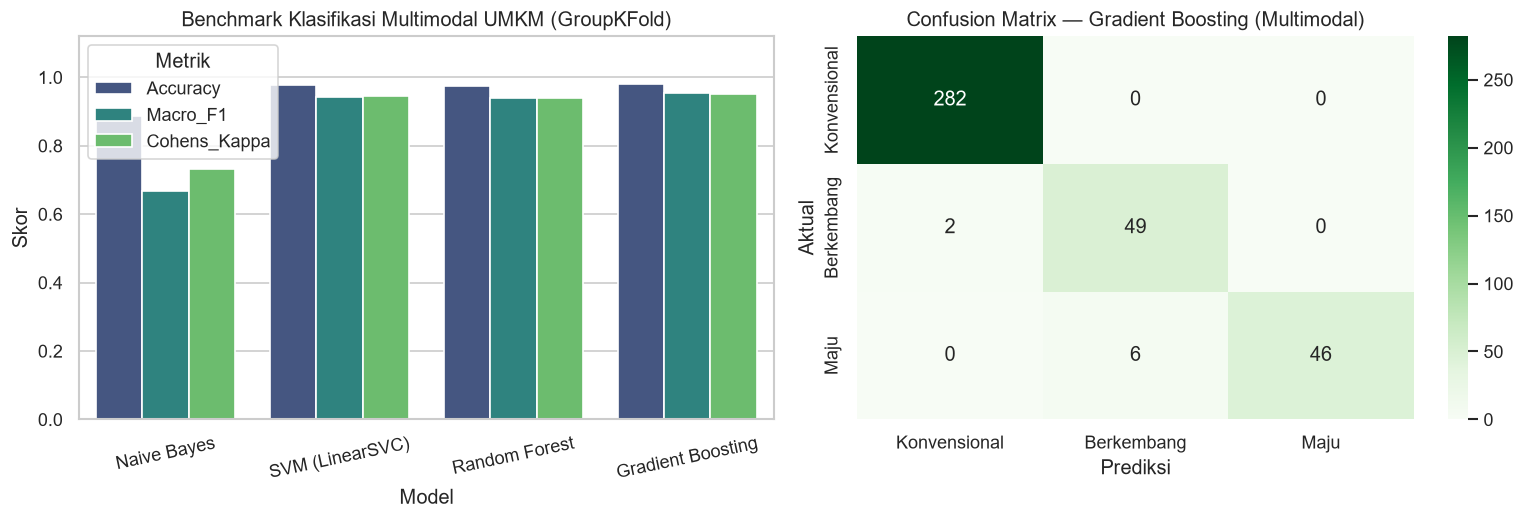

In [3]:
from sklearn.cluster import KMeans
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix, davies_bouldin_score, f1_score, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

FEATURE_COLS = [
    'rating', 'jumlah_ulasan', 'indikator_qris', 'indikator_pos', 'indikator_edc', 'indikator_ojol',
    'review_count', 'avg_word_count', 'text_qris', 'text_ojol_alias', 'text_pos', 'text_edc',
    'photo_count', 'vis_qris', 'vis_online', 'vis_pos', 'vis_edc',
]
LABEL_NAMES = {0: 'Konvensional', 1: 'Berkembang', 2: 'Maju'}

def prepare_feature_frame(df):
    df = df.copy()
    if 'text_ojol_alias' not in df.columns:
        df['text_ojol_alias'] = df.get('text_online', 0.0)
    for c in FEATURE_COLS:
        if c not in df.columns:
            df[c] = 0.0
        df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0.0)
    return df

def derive_target_class(df):
    n_ind = df['indikator_qris'].astype(int) + df['indikator_ojol'].astype(int) + df['indikator_pos'].astype(int) + df['indikator_edc'].astype(int)
    y = np.zeros(len(df), dtype=int)
    y[n_ind == 1] = 1
    y[n_ind >= 2] = 2
    return y

df_feat = prepare_feature_frame(pd.read_parquet(ENV['feat_store']))
scaler_umkm = StandardScaler().fit(df_feat[FEATURE_COLS].values.astype(np.float32))
X_sc = scaler_umkm.transform(df_feat[FEATURE_COLS].values.astype(np.float32))
y_cls = derive_target_class(df_feat)
y_reg = df_feat['skor_kematangan_kontinu'].values.astype(np.float32)
groups = df_feat['kecamatan'].to_numpy(dtype=str)

km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_sc)
print(f'[Clustering] K-Means (k=3) -> Silhouette: {silhouette_score(X_sc, km.labels_):.4f} | Davies-Bouldin: {davies_bouldin_score(X_sc, km.labels_):.4f}')

gkf = GroupKFold(n_splits=5)
clf_builders = {
    'Naive Bayes': lambda: GaussianNB(),
    'SVM (LinearSVC)': lambda: LinearSVC(random_state=42, dual='auto', max_iter=3000),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, class_weight='balanced'),
    'Gradient Boosting': lambda: GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42),
}
adj_rows, best_cm = [], None
for cname, build_fn in clf_builders.items():
    yt, yp = [], []
    for tr, te in gkf.split(X_sc, y_cls, groups):
        c = build_fn().fit(X_sc[tr], y_cls[tr])
        yt.extend(y_cls[te]); yp.extend(c.predict(X_sc[te]))
    adj_rows.append({
        'Model': cname,
        'Accuracy': round(accuracy_score(yt, yp), 4),
        'Macro_F1': round(f1_score(yt, yp, average='macro'), 4),
        'Cohens_Kappa': round(cohen_kappa_score(yt, yp), 4),
    })
    if cname == 'Gradient Boosting':
        best_cm = confusion_matrix(yt, yp)

yr_t, yr_p = [], []
for tr, te in gkf.split(X_sc, y_reg, groups):
    reg = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42).fit(X_sc[tr], y_reg[tr])
    yr_t.extend(y_reg[te]); yr_p.extend(reg.predict(X_sc[te]))
print(f'[Regression] RF Regressor (GroupKFold) -> R2: {r2_score(yr_t, yr_p):.4f} | RMSE: {np.sqrt(mean_squared_error(yr_t, yr_p)):.4f}')

df_adj_bench = pd.DataFrame(adj_rows)
display(df_adj_bench)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.5))
melted = df_adj_bench.melt(id_vars='Model', value_vars=['Accuracy', 'Macro_F1', 'Cohens_Kappa'], var_name='Metrik', value_name='Skor')
sns.barplot(data=melted, x='Model', y='Skor', hue='Metrik', palette='viridis', ax=axes[0])
axes[0].set_title('Benchmark Klasifikasi Multimodal UMKM (GroupKFold)')
axes[0].set_ylim(0, 1.12); axes[0].tick_params(axis='x', rotation=12)
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Greens', xticklabels=list(LABEL_NAMES.values()), yticklabels=list(LABEL_NAMES.values()), ax=axes[1])
axes[1].set_title('Confusion Matrix — Gradient Boosting (Multimodal)')
axes[1].set_xlabel('Prediksi'); axes[1].set_ylabel('Aktual')
save_and_show('01_multimodal_benchmark_dan_confusion_matrix.png')

## 3. Evaluasi Dataset Gambar Serupa (Padang Cuisine 993 Foto), Dokumen (MIDD & CORD-v2), & Ringkasan Terpadu

In [4]:
adj_json = json.loads((ENV['modif_res'] / 'adjust_summary.json').read_text(encoding='utf-8'))
print('=== EVALUASI DATASET GAMBAR MASAKAN INDONESIA SERUPA (fahmindra/padang-cuisine, 993 Foto, 9 Kelas) ===')
display(pd.DataFrame(adj_json['padang_food_images']['benchmark']))

doc_eval_tbl = pd.DataFrame([
    {'Dataset_Dokumen': 'MIDD Multi-Layout Invoice (699 Valid CSV)', 'Tugas': 'Klasifikasi 4 Layout (TF-IDF + LinearSVC)', 'Accuracy': adj_json['midd_documents']['layout_clf_svm_acc'], 'Macro_F1': adj_json['midd_documents']['layout_clf_svm_f1']},
    {'Dataset_Dokumen': 'MIDD Multi-Layout Invoice (699 Valid CSV)', 'Tugas': 'Klasifikasi 4 Layout (TF-IDF + Random Forest)', 'Accuracy': adj_json['midd_documents']['layout_clf_rf_acc'], 'Macro_F1': adj_json['midd_documents']['layout_clf_rf_f1']},
    {'Dataset_Dokumen': 'CORD-v2 Struk Restoran Indonesia (200 Struk)', 'Tugas': 'Klasifikasi Pembayaran Non-Tunai (Random Forest)', 'Accuracy': adj_json['cord_receipts']['digital_payment_rf_acc'], 'Macro_F1': adj_json['cord_receipts']['digital_payment_rf_f1']},
])
display(doc_eval_tbl)
display(pd.read_csv(ENV['modif_res'] / 'adjust_vs_repeat_multimodal_summary.csv'))
display(pd.read_csv(ENV['eval_res'] / 'model_comparison_summary.csv'))

=== EVALUASI DATASET GAMBAR MASAKAN INDONESIA SERUPA (fahmindra/padang-cuisine, 993 Foto, 9 Kelas) ===


,Model,Test_Accuracy,Test_Macro_F1
0,Random Forest,0.6333,0.6191
1,LinearSVC,0.5889,0.5832
2,MLP (Neural Net),0.5889,0.5928


,Dataset_Dokumen,Tugas,Accuracy,Macro_F1
0,MIDD Multi-Layout Invoice (699 Valid CSV),Klasifikasi 4 Layout (TF-IDF + LinearSVC),0.9986,0.9991
1,MIDD Multi-Layout Invoice (699 Valid CSV),Klasifikasi 4 Layout (TF-IDF + Random Forest),0.9986,0.9991
2,CORD-v2 Struk Restoran Indonesia (200 Struk),Klasifikasi Pembayaran Non-Tunai (Random Forest),0.6350,0.4961


,Modalitas_Tahap,Sumber_Dataset,Metode_Utama,Metrik_Utama
0,1. Repeat Jurnal Utama (Tabular 48 SWK),"Satu Data Surabaya (Selayanti et al., 2024)",AHC Complete Linkage (k=3),Cophenetic = 0.8566 | Silhouette = 0.4893 (Pap...
1,2A. Modifikasi Gambar + Teks/Numerik UMKM,549 Foto (279.99 MB) + 385 UMKM + 1.164 Ulasan...,"K-Means, Autoencoder, RF, Gradient Boosting, P...","GB Acc = 0.9792, F1 = 0.9533 | K-Means Sil = 0..."
2,2B. Gambar Masakan Indonesia Serupa (Padang Cu...,"HF fahmindra/padang-cuisine (ODbL, 993 foto, 9...",HSV/Lab Spatial Pyramid + Sobel Texture + Rand...,"Test Acc = 0.6333, Macro-F1 = 0.6191 (9 Kelas ..."
3,3A. Dokumen Invoice (MIDD - 708 CSV IOB),MIDD Zenodo 10.5281/zenodo.5113009 (Baviskar e...,TF-IDF + LinearSVC & Random Forest (4-Layout C...,"SVM Acc = 0.9986, F1 = 0.9991 | RF Acc = 0.9986"
4,3B. Dokumen Struk Indonesia (CORD-v2),"CORD-v2 (Park et al., 2019; HF iqbal-rizanta/c...",Receipt Metadata Feature Extraction + RF Payme...,"Acc = 0.6350, F1 = 0.4961 | Median Struk Rp 48..."


,Kategori,Tugas,Model,Metrik_Utama
0,Machine Learning (.pkl),Clustering,KMeans(k=3),Silhouette = 0.4756
1,Machine Learning (.pkl),Classification,RandomForestClassifier,Macro-F1 = 0.9402 | Kappa = 0.9388
2,Machine Learning (.pkl),Regression,RandomForestRegressor,R2 = 0.9768 | RMSE = 2.9352
3,Deep Learning (.pt/.pth/.h5),Clustering,DeepClusteringAutoencoder(latent=6)+KMeans,Latent Silhouette = 0.4834
4,Deep Learning (.pt/.pth/.h5),Classification,DeepMaturityClassifier(MLP),Macro-F1 = 1.0
5,Deep Learning (.pt/.pth/.h5),Regression,DeepMaturityRegressor(MLP),R2 = 0.9993 | RMSE = 0.5039


## 4. Uji Kesepakatan Lintas-Sumber (`Cohen's Kappa` SWK) & Uji Inferensi Model

In [5]:
df_foto = pd.read_parquet(ENV['clean_tab'] / 'foto.parquet')
df_swk_off = df_foto[df_foto['sumber'] == 'survei_lapangan_swk'].copy()
gt_qris = df_swk_off['label_ground_truth'].isin(['Berkembang', 'Maju']).astype(int).values
obs_qris = df_swk_off['has_qris'].astype(int).values if 'has_qris' in df_swk_off.columns else (df_swk_off['label_id'] >= 1).astype(int).values
kappa_swk = cohen_kappa_score(gt_qris, obs_qris) if len(set(obs_qris)) > 1 else 1.0
print(f'Sampel Survei Lapangan SWK : {len(df_swk_off)} foto | Kappa QRIS: {kappa_swk:.4f}')

sample_in = {'nama_umkm': 'Stan Kuliner SWK Sukolilo', 'kecamatan': 'Sukolilo', 'rating': 4.6, 'jumlah_ulasan': 42, 'indikator_qris': 1, 'indikator_ojol': 1, 'indikator_pos': 0, 'indikator_edc': 0}
try:
    from app.server.inference_service import UMKMInferenceService
    sample_pred = UMKMInferenceService().predict_all(sample_in)
except Exception:
    gb_full = GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.08, random_state=42).fit(X_sc, y_cls)
    rf_reg_full = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42).fit(X_sc, y_reg)
    x_one = scaler_umkm.transform(prepare_feature_frame(pd.DataFrame([sample_in]))[FEATURE_COLS].values.astype(np.float32))
    sample_pred = {'ml_clustering_id': int(km.predict(x_one)[0]), 'ml_classification_label': LABEL_NAMES[int(gb_full.predict(x_one)[0])], 'ml_regression_score': round(float(rf_reg_full.predict(x_one)[0]), 2)}
print('Uji Inferensi Model (ML & DL):')
for k, v in sample_pred.items():
    print(f'  - {k:<26}: {v}')

Sampel Survei Lapangan SWK : 44 foto | Kappa QRIS: 0.5600


Uji Inferensi Model (ML & DL):
  - nama_umkm                 : Stan Kuliner SWK Sukolilo
  - kecamatan                 : Sukolilo
  - ml_clustering_cluster     : 1
  - ml_classification_label   : Maju
  - ml_regression_score       : 56.6
  - dl_clustering_cluster     : 0
  - dl_classification_label   : Berkembang
  - dl_regression_score       : 100.0
  - rekomendasi               : Perluasan akses pembiayaan mikro berbasis rekam jejak transaksi digital dan promosi lintas kanal.
